# 07 · Metrik, perubahan berpasangan, dan sensitivitas

**Bab 3 Subbab 3.10.**

- **Macro-F1** (utama): rata-rata F1 BUY, HOLD, SELL berbobot sama; F1 kelas dengan penyebut nol = 0.
- **Balanced accuracy** (pendamping): rata-rata recall tiga kelas; **tidak terdefinisi** bila satu kelas tidak muncul
  pada data uji.
- **Perubahan berpasangan** $\Delta = $ skor(K2) − skor(K1) dan skor(K3) − skor(K2), pada periode, model, dan bar uji
  yang sama. Ringkasan: rata-rata tanpa bobot, median, simpangan baku sampel, jumlah periode positif, jumlah pasangan.
- Analisis bersifat **deskriptif**. Tujuh periode saling bergantung (jendela latih mengembang), jadi tidak ada uji
  hipotesis atau nilai-*p*.
- Perubahan positif, nol, atau negatif sama-sama menjawab pertanyaan penelitian. Hasil tidak ditafsirkan sebagai
  keuntungan transaksi, efek kausal, atau kontribusi tiap fitur.

**Input:** `06_prediksi.parquet`, `06_kegagalan.csv` · **Output:** tabel `07_*.csv`, `07_ringkasan.json`

In [1]:
import tomllib
from pathlib import Path

# Cari folder proyek (folder yang memuat configs/phase4-p0.toml) agar notebook bisa dijalankan dari mana saja.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/phase4-p0.toml").exists())
CFG = tomllib.loads((ROOT / "configs/phase4-p0.toml").read_text(encoding="utf-8"))
OUT = ROOT / "data/interim/phase4-p0"     # folder hasil; diabaikan Git karena memuat data vendor
OUT.mkdir(parents=True, exist_ok=True)

In [2]:
import hashlib
import json

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score, recall_score

pred = pd.read_parquet(OUT / "06_prediksi.parquet")
kegagalan = pd.read_csv(OUT / "06_kegagalan.csv")
KELAS = CFG["label"]["class_order"]
URUT_CM = CFG["label"]["confusion_order"]
PERIODE = [p[0] for p in CFG["validasi"]["periode_uji"]]
NAMA = {"regresi_logistik": "Regresi Logistik", "xgboost": "XGBoost", "mayoritas": "Kelas mayoritas"}
print("Kegagalan evaluasi:", len(kegagalan))
kegagalan

Kegagalan evaluasi: 0


,ambang,periode,model,konfigurasi,alasan


## 1. Skor per periode

In [3]:
def skor(g):
    benar, prediksi = g["benar"].to_numpy(), g["prediksi"].to_numpy()
    lengkap = all((benar == k).any() for k in KELAS)
    return pd.Series({
        "n_uji": len(g),
        "macro_f1": f1_score(benar, prediksi, labels=KELAS, average="macro", zero_division=0),
        "balanced_accuracy": recall_score(benar, prediksi, labels=KELAS, average="macro", zero_division=0) if lengkap else np.nan,
    })


kunci = ["ambang", "analisis", "model", "konfigurasi", "periode"]
metrik = pred.groupby(kunci, sort=False)[["benar", "prediksi"]].apply(skor).reset_index()
metrik.to_csv(OUT / "07_metrik_per_periode.csv", index=False)
print("Balanced accuracy tidak terdefinisi:", int(metrik["balanced_accuracy"].isna().sum()), "baris")

utama = metrik[(metrik["ambang"] == 0.5) & (metrik["analisis"] == "disetel")]
utama.pivot_table(index="periode", columns=["model", "konfigurasi"], values="macro_f1", sort=False).reindex(PERIODE).round(4)

Balanced accuracy tidak terdefinisi: 0 baris


model        regresi_logistik                 xgboost                
konfigurasi                K1      K2      K3      K1      K2      K3
periode                                                              
2023-H1                0.4238  0.4232  0.4151  0.4160  0.4167  0.4201
2023-H2                0.3917  0.3927  0.3899  0.4021  0.3950  0.3897
2024-H1                0.3957  0.3979  0.3947  0.3986  0.3969  0.3961
2024-H2                0.3884  0.3888  0.3866  0.3946  0.4009  0.3993
2025-H1                0.3899  0.3872  0.3910  0.3933  0.3822  0.3914
2025-H2                0.3788  0.3787  0.3840  0.3717  0.3760  0.3778
2026-Jan-Jul           0.3767  0.3772  0.3799  0.3781  0.3793  0.3758

## 2. Hasil utama: ambang 0,5 · penyetelan per konfigurasi

Rerata tujuh periode tanpa bobot, ditambah diagnostik kelas mayoritas pada bar uji yang sama.

In [4]:
diag = metrik[(metrik["ambang"] == 0.5) & (metrik["model"] == "mayoritas")]
tabel_utama = pd.concat([
    utama.groupby(["model", "konfigurasi"])[["macro_f1", "balanced_accuracy"]].mean(),
    diag.groupby(["model", "konfigurasi"])[["macro_f1", "balanced_accuracy"]].mean(),
]).rename(index=NAMA, level=0)
tabel_utama.to_csv(OUT / "07_rerata_utama.csv")
tabel_utama.round(6)

macro_f1  balanced_accuracy
model            konfigurasi                             
Regresi Logistik K1           0.392154           0.395686
                 K2           0.392243           0.395948
                 K3           0.391609           0.396018
XGBoost          K1           0.393499           0.397577
                 K2           0.392416           0.397104
                 K3           0.392895           0.397445
Kelas mayoritas  -            0.216652           0.333333

## 3. Perubahan berpasangan K2 − K1 dan K3 − K2

In [5]:
def skor_konfig(m, konfig, analisis, metrik_nama):
    """K1 selalu memakai hasil "disetel"; pada analisis parameter tetap, K2/K3 memakai parameter K1."""
    pilih = "disetel" if konfig == "K1" else analisis
    return m[(m["konfigurasi"] == konfig) & (m["analisis"] == pilih)].set_index("periode")[metrik_nama]


def ringkas_delta(metrik, ambang, analisis, metrik_nama):
    baris = []
    for model in ("regresi_logistik", "xgboost"):
        m = metrik[(metrik["ambang"] == ambang) & (metrik["model"] == model)]
        for kiri, kanan in (("K1", "K2"), ("K2", "K3")):
            d = (skor_konfig(m, kanan, analisis, metrik_nama) - skor_konfig(m, kiri, analisis, metrik_nama)).reindex(PERIODE).dropna()
            baris.append({
                "model": NAMA[model], "perubahan": f"{kanan} − {kiri}",
                "pasangan": f"{len(d)}/{len(PERIODE)}",
                "rerata": d.mean() if len(d) else np.nan,
                "median": d.median() if len(d) else np.nan,
                "simpangan_baku": d.std(ddof=1) if len(d) >= 2 else np.nan,
                "periode_positif": f"{int((d > 0).sum())}/{len(d)}",
            })
    return pd.DataFrame(baris)


delta_utama = pd.concat({m: ringkas_delta(metrik, 0.5, "disetel", m) for m in ("macro_f1", "balanced_accuracy")},
                        names=["metrik"]).reset_index(level=0)
delta_utama.to_csv(OUT / "07_delta_utama.csv", index=False)
delta_utama.round(6)

,metrik,model,perubahan,pasangan,rerata,median,simpangan_baku,periode_positif
0,macro_f1,Regresi Logistik,K2 − K1,7/7,0.000089,0.000347,0.001539,4/7
1,macro_f1,Regresi Logistik,K3 − K2,7/7,-0.000634,-0.002167,0.004770,3/7
2,macro_f1,XGBoost,K2 − K1,7/7,-0.001083,0.000707,0.006187,4/7
3,macro_f1,XGBoost,K3 − K2,7/7,0.000479,-0.000808,0.004859,3/7
0,balanced_accuracy,Regresi Logistik,K2 − K1,7/7,0.000262,0.000134,0.001714,4/7
1,balanced_accuracy,Regresi Logistik,K3 − K2,7/7,0.000070,0.000155,0.004150,4/7
2,balanced_accuracy,XGBoost,K2 − K1,7/7,-0.000473,0.000506,0.006290,4/7
3,balanced_accuracy,XGBoost,K3 − K2,7/7,0.000341,-0.000627,0.005102,3/7


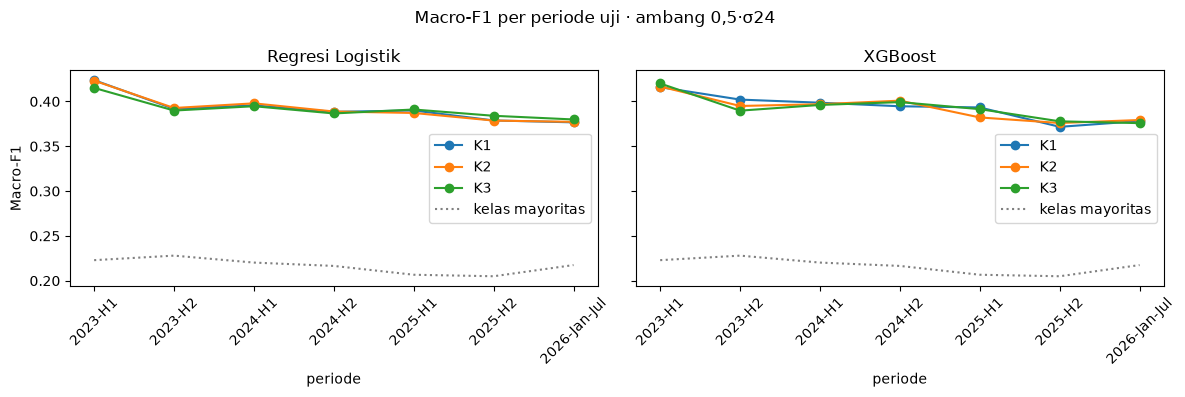

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, model in zip(axes, ("regresi_logistik", "xgboost")):
    t = utama[utama["model"] == model].pivot(index="periode", columns="konfigurasi", values="macro_f1").reindex(PERIODE)
    t.plot(ax=ax, marker="o")
    d = diag.set_index("periode")["macro_f1"].reindex(PERIODE)
    ax.plot(range(len(PERIODE)), d.to_numpy(), ls=":", c="gray", label="kelas mayoritas")
    ax.set_xticks(range(len(PERIODE)), PERIODE, rotation=45)
    ax.set_title(NAMA[model])
    ax.legend()
axes[0].set_ylabel("Macro-F1")
fig.suptitle("Macro-F1 per periode uji · ambang 0,5·σ24")
plt.tight_layout()

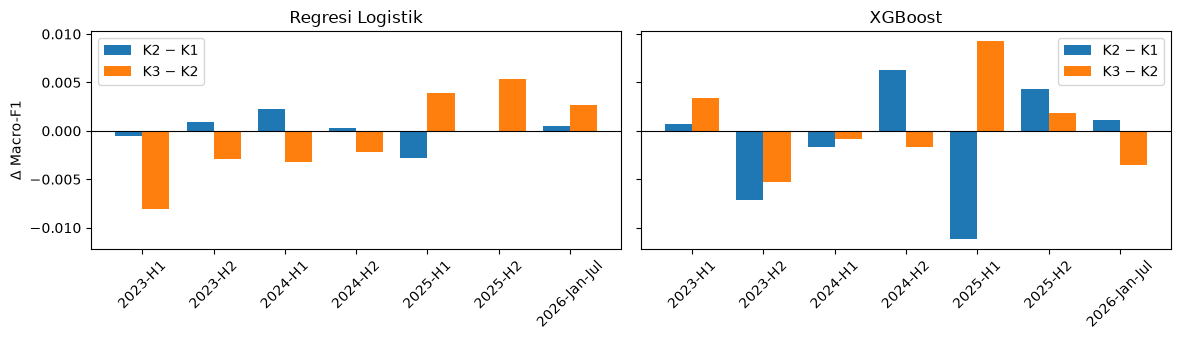

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, model in zip(axes, ("regresi_logistik", "xgboost")):
    t = utama[utama["model"] == model].pivot(index="periode", columns="konfigurasi", values="macro_f1").reindex(PERIODE)
    lebar = 0.38
    x = np.arange(len(PERIODE))
    ax.bar(x - lebar / 2, t["K2"] - t["K1"], lebar, label="K2 − K1")
    if "K3" in t:
        ax.bar(x + lebar / 2, t["K3"] - t["K2"], lebar, label="K3 − K2")
    ax.axhline(0, c="black", lw=0.8)
    ax.set_xticks(x, PERIODE, rotation=45)
    ax.set_title(NAMA[model])
    ax.legend()
axes[0].set_ylabel("Δ Macro-F1")
plt.tight_layout()

## 4. Matriks kebingungan gabungan tujuh periode

Baris = label benar, kolom = prediksi, urutan BUY, HOLD, SELL.

In [8]:
for model in ("regresi_logistik", "xgboost"):
    for konfig in sorted(utama["konfigurasi"].unique()):
        g = pred[(pred["ambang"] == 0.5) & (pred["analisis"] == "disetel") & (pred["model"] == model) & (pred["konfigurasi"] == konfig)]
        cm = pd.DataFrame(confusion_matrix(g["benar"], g["prediksi"], labels=URUT_CM), index=URUT_CM, columns=URUT_CM)
        print(f"{NAMA[model]} · {konfig}")
        display(cm)

Regresi Logistik · K1


,BUY,HOLD,SELL
BUY,1444,2392,1564
HOLD,1671,5771,2150
SELL,1262,2097,1542


Regresi Logistik · K2


,BUY,HOLD,SELL
BUY,1456,2367,1577
HOLD,1691,5773,2128
SELL,1282,2088,1531


Regresi Logistik · K3


,BUY,HOLD,SELL
BUY,1463,2228,1709
HOLD,1774,5516,2302
SELL,1302,1944,1655


... (2 outputs left out)

XGBoost · K2


,BUY,HOLD,SELL
BUY,1670,1950,1780
HOLD,2109,5024,2459
SELL,1390,1762,1749


XGBoost · K3


,BUY,HOLD,SELL
BUY,1642,2003,1755
HOLD,2078,5075,2439
SELL,1377,1771,1753


## 5. Sensitivitas ambang 0,25 dan 1,0

In [9]:
sens_ambang = pd.concat({
    a: ringkas_delta(metrik, a, "disetel", "macro_f1") for a in CFG["label"]["threshold_sensitivitas"]
}, names=["ambang"]).reset_index(level=0)
sens_ambang.to_csv(OUT / "07_sensitivitas_ambang.csv", index=False)
sens_ambang.round(6)

,ambang,model,perubahan,pasangan,rerata,median,simpangan_baku,periode_positif
0,0.25,Regresi Logistik,K2 − K1,7/7,0.003965,0.003791,0.002066,7/7
1,0.25,Regresi Logistik,K3 − K2,7/7,-0.001034,0.000853,0.007754,4/7
2,0.25,XGBoost,K2 − K1,7/7,-0.004523,-0.001043,0.008168,1/7
3,0.25,XGBoost,K3 − K2,7/7,-0.000310,0.000024,0.010183,4/7
0,1.00,Regresi Logistik,K2 − K1,7/7,0.001081,-0.000258,0.005905,3/7
1,1.00,Regresi Logistik,K3 − K2,7/7,-0.002286,-0.001299,0.004393,2/7
2,1.00,XGBoost,K2 − K1,7/7,0.000116,0.000033,0.007996,4/7
3,1.00,XGBoost,K3 − K2,7/7,0.009021,0.008252,0.005722,7/7


## 6. Sensitivitas parameter tetap (hiperparameter K1 dipakai ulang)

Membantu memisahkan efek fitur dari efek penyetelan ulang. Dilaporkan terpisah dan tidak menggantikan hasil utama.

In [10]:
sens_tetap = pd.concat({
    a: ringkas_delta(metrik, a, "parameter_tetap_k1", "macro_f1")
    for a in [CFG["label"]["threshold_utama"], *CFG["label"]["threshold_sensitivitas"]]
}, names=["ambang"]).reset_index(level=0)
sens_tetap.to_csv(OUT / "07_sensitivitas_parameter_tetap.csv", index=False)
sens_tetap.round(6)

,ambang,model,perubahan,pasangan,rerata,median,simpangan_baku,periode_positif
0,0.50,Regresi Logistik,K2 − K1,7/7,0.000764,0.000576,0.002407,5/7
1,0.50,Regresi Logistik,K3 − K2,7/7,-0.001368,-0.002709,0.004913,3/7
2,0.50,XGBoost,K2 − K1,7/7,-0.001877,-0.001690,0.008695,2/7
3,0.50,XGBoost,K3 − K2,7/7,0.001104,-0.000037,0.004817,3/7
0,0.25,Regresi Logistik,K2 − K1,7/7,0.004314,0.003791,0.001704,7/7
1,0.25,Regresi Logistik,K3 − K2,7/7,-0.000394,0.001736,0.007674,4/7
2,0.25,XGBoost,K2 − K1,7/7,-0.005377,-0.005187,0.007050,2/7
3,0.25,XGBoost,K3 − K2,7/7,0.001925,0.000858,0.007049,5/7
0,1.00,Regresi Logistik,K2 − K1,7/7,0.000095,-0.000908,0.005715,3/7
1,1.00,Regresi Logistik,K3 − K2,7/7,-0.000953,0.000035,0.004286,4/7
